# Preamble

In [1]:
# General Imports
import sys
import os
import numpy as np

# Data processesing imports
import pandas as pd
import sqlite3

# Visualization imports
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

In [2]:
# Initialize SQLite Connection and Cursor objects
conn = sqlite3.connect('data/revolut_home_task.db')
cursor = conn.cursor()

# Data Overview

## Number of users, cities, countries

In [3]:
# Query number of distinct users, by city and country.
with open('sql-queries/user-city-country.sql','r') as f:
    query = f.read()
    f.close()

user_ref_data = pd.read_sql(query,conn)

In [4]:
## First we want to double check that each user corresponds to a unique city/country combination
user_entry_count = user_ref_data\
    .reset_index()\
    .groupby('user_id')\
    .agg(unique_entry_count = ('index','count'))

if (user_entry_count.unique_entry_count > 1).any():
    print('Instances of multiple cities/countries per user found')
else:
    print('Each user has one city/country')

Instances of multiple cities/countries per user found


In [5]:
## Create a table containing latest city/country combination per user
cursor.execute("DROP TABLE IF EXISTS latest_user_address")
with open('sql-queries/latest-user-address.sql','r') as f:
    query = f.read()
    f.close()
cursor.execute(query)
print("Latest user addresses queried and loaded to latest_user_address")

Latest user addresses queried and loaded to latest_user_address


In [6]:
## Query the User address table
user_addresses = pd.read_sql("SELECT * FROM latest_user_address",conn)

## Group by city and country, and aggregate
user_address_summary = user_addresses\
    .groupby(['user_country','user_city'])\
    .agg(users=('user_id','count'))\
    .sort_values(by='users',ascending=False)

user_address_summary.head()

,,users
user_country,user_city,
United Kingdom,London,7344
Ireland,Dublin,3671
Hungary,Budapest,2518
France,Paris,2141
Poland,Warszawa,1686


In [7]:
## Export to CSV
user_address_summary.to_csv('outputs/user_locations.csv')

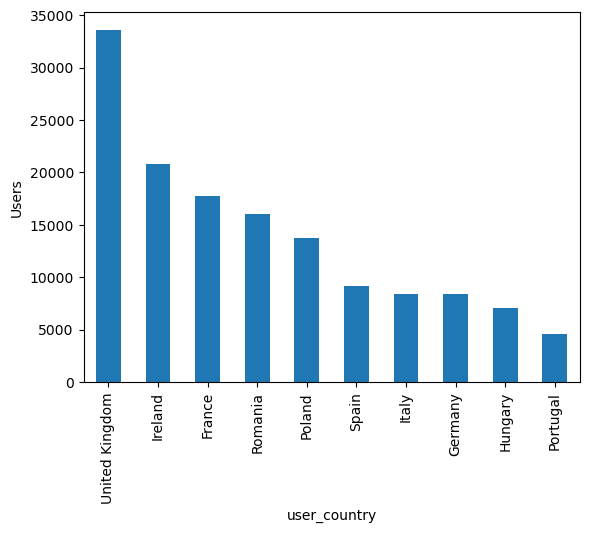

In [8]:
## Plot bar chart of user counts in top 10 countries
users_by_country_plot = user_address_summary\
    .reset_index()\
    .groupby('user_country')\
    .agg(users = ('users','sum'))\
    .sort_values(by='users',ascending=False)\
    .head(10)\
    .plot(y='users',kind='bar',legend=False,ylabel='Users')
users_by_country_plot.get_figure().savefig('figures/users_per_country.png')

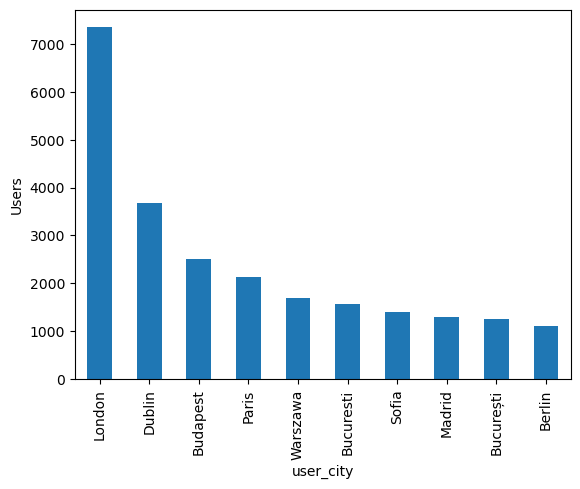

In [9]:
## Plot bar chart of user counts by city for top 10 cities
users_by_city_plot = user_address_summary\
    .reset_index()\
    .groupby('user_city')\
    .agg(users = ('users','sum'))\
    .sort_values(by='users',ascending=False)\
    .head(10)\
    .plot(kind='bar',legend=False,ylabel='Users')
users_by_city_plot.get_figure().savefig('figures/users_by_city_plot.png')

In [13]:
# Print count of distinct users, countries, cities
no_users = user_address_summary.users.sum()
no_cities = np.unique(
    user_address_summary\
        .reset_index()\
        .user_city\
        .to_numpy()
).shape[0]
no_countries = np.unique(
    user_address_summary\
        .reset_index()\
        .user_country\
        .to_numpy()
).shape[0]

print('Distinct users: ', no_users)
print('Distinct user countries: ', no_countries)
print('Distinct user cities: ', no_cities)

Distinct users:  183532
Distinct user countries:  62
Distinct user cities:  35957


## Users by age group

In [19]:
# Query latest user age, by user type and country

with open('sql-queries/latest-user-age-country.sql','r') as f:
    query = f.read()
    f.close()
user_age_summary = pd.read_sql(query, conn)
user_age_summary.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 524 entries, 0 to 523
Data columns (total 4 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   age_group     442 non-null    object
 1   user_country  524 non-null    object
 2   user_type     524 non-null    object
 3   users         524 non-null    int64 
dtypes: int64(1), object(3)
memory usage: 16.5+ KB


In [20]:
# Check which user type has the most null age grouups
user_age_summary[user_age_summary.age_group.isnull()].groupby('user_type').agg(users=('users','sum')).head(10)

,users
user_type,
BUSINESS,2328
BUSINESS_USER,2
COMPANY,9
PERSONAL,1328
YOUTH,2


In [ ]:
# 

In [21]:
tables = pd.read_sql(
    "SELECT name, type FROM sqlite_master WHERE type IN ('table','view')",
    conn
)
print(tables)

                  name   type
0      user_monthly_gp  table
1  latest_user_address  table


# Postamble

In [27]:
cursor.close()
conn.close()